FIRST 5 ROWS
   Employee_ID   Age  Gender Department   Job_Role  Job_Level Work_Location  \
0            1   NaN    Male      Sales        NaN        1.0        Remote   
1            2  40.0    Male      Sales    Analyst        4.0     Bangalore   
2            3  38.0  Female         HR  Executive        3.0     Hyderabad   
3            4  36.0    Male      Sales  Executive        5.0           NaN   
4            5  60.0    Male        NaN    Analyst        4.0        Mumbai   

   Monthly_Income Overtime  Years_At_Company  Performance_Rating  \
0             NaN      Yes              18.0                 3.0   
1        107052.0      NaN              15.0                 2.0   
2        114358.0      Yes               7.0                 5.0   
3         66214.0      Yes              11.0                 NaN   
4         54725.0       No              15.0                 NaN   

   Job_Satisfaction  Work_Life_Balance Attrition    Attrition_Reason  
0               1.0             

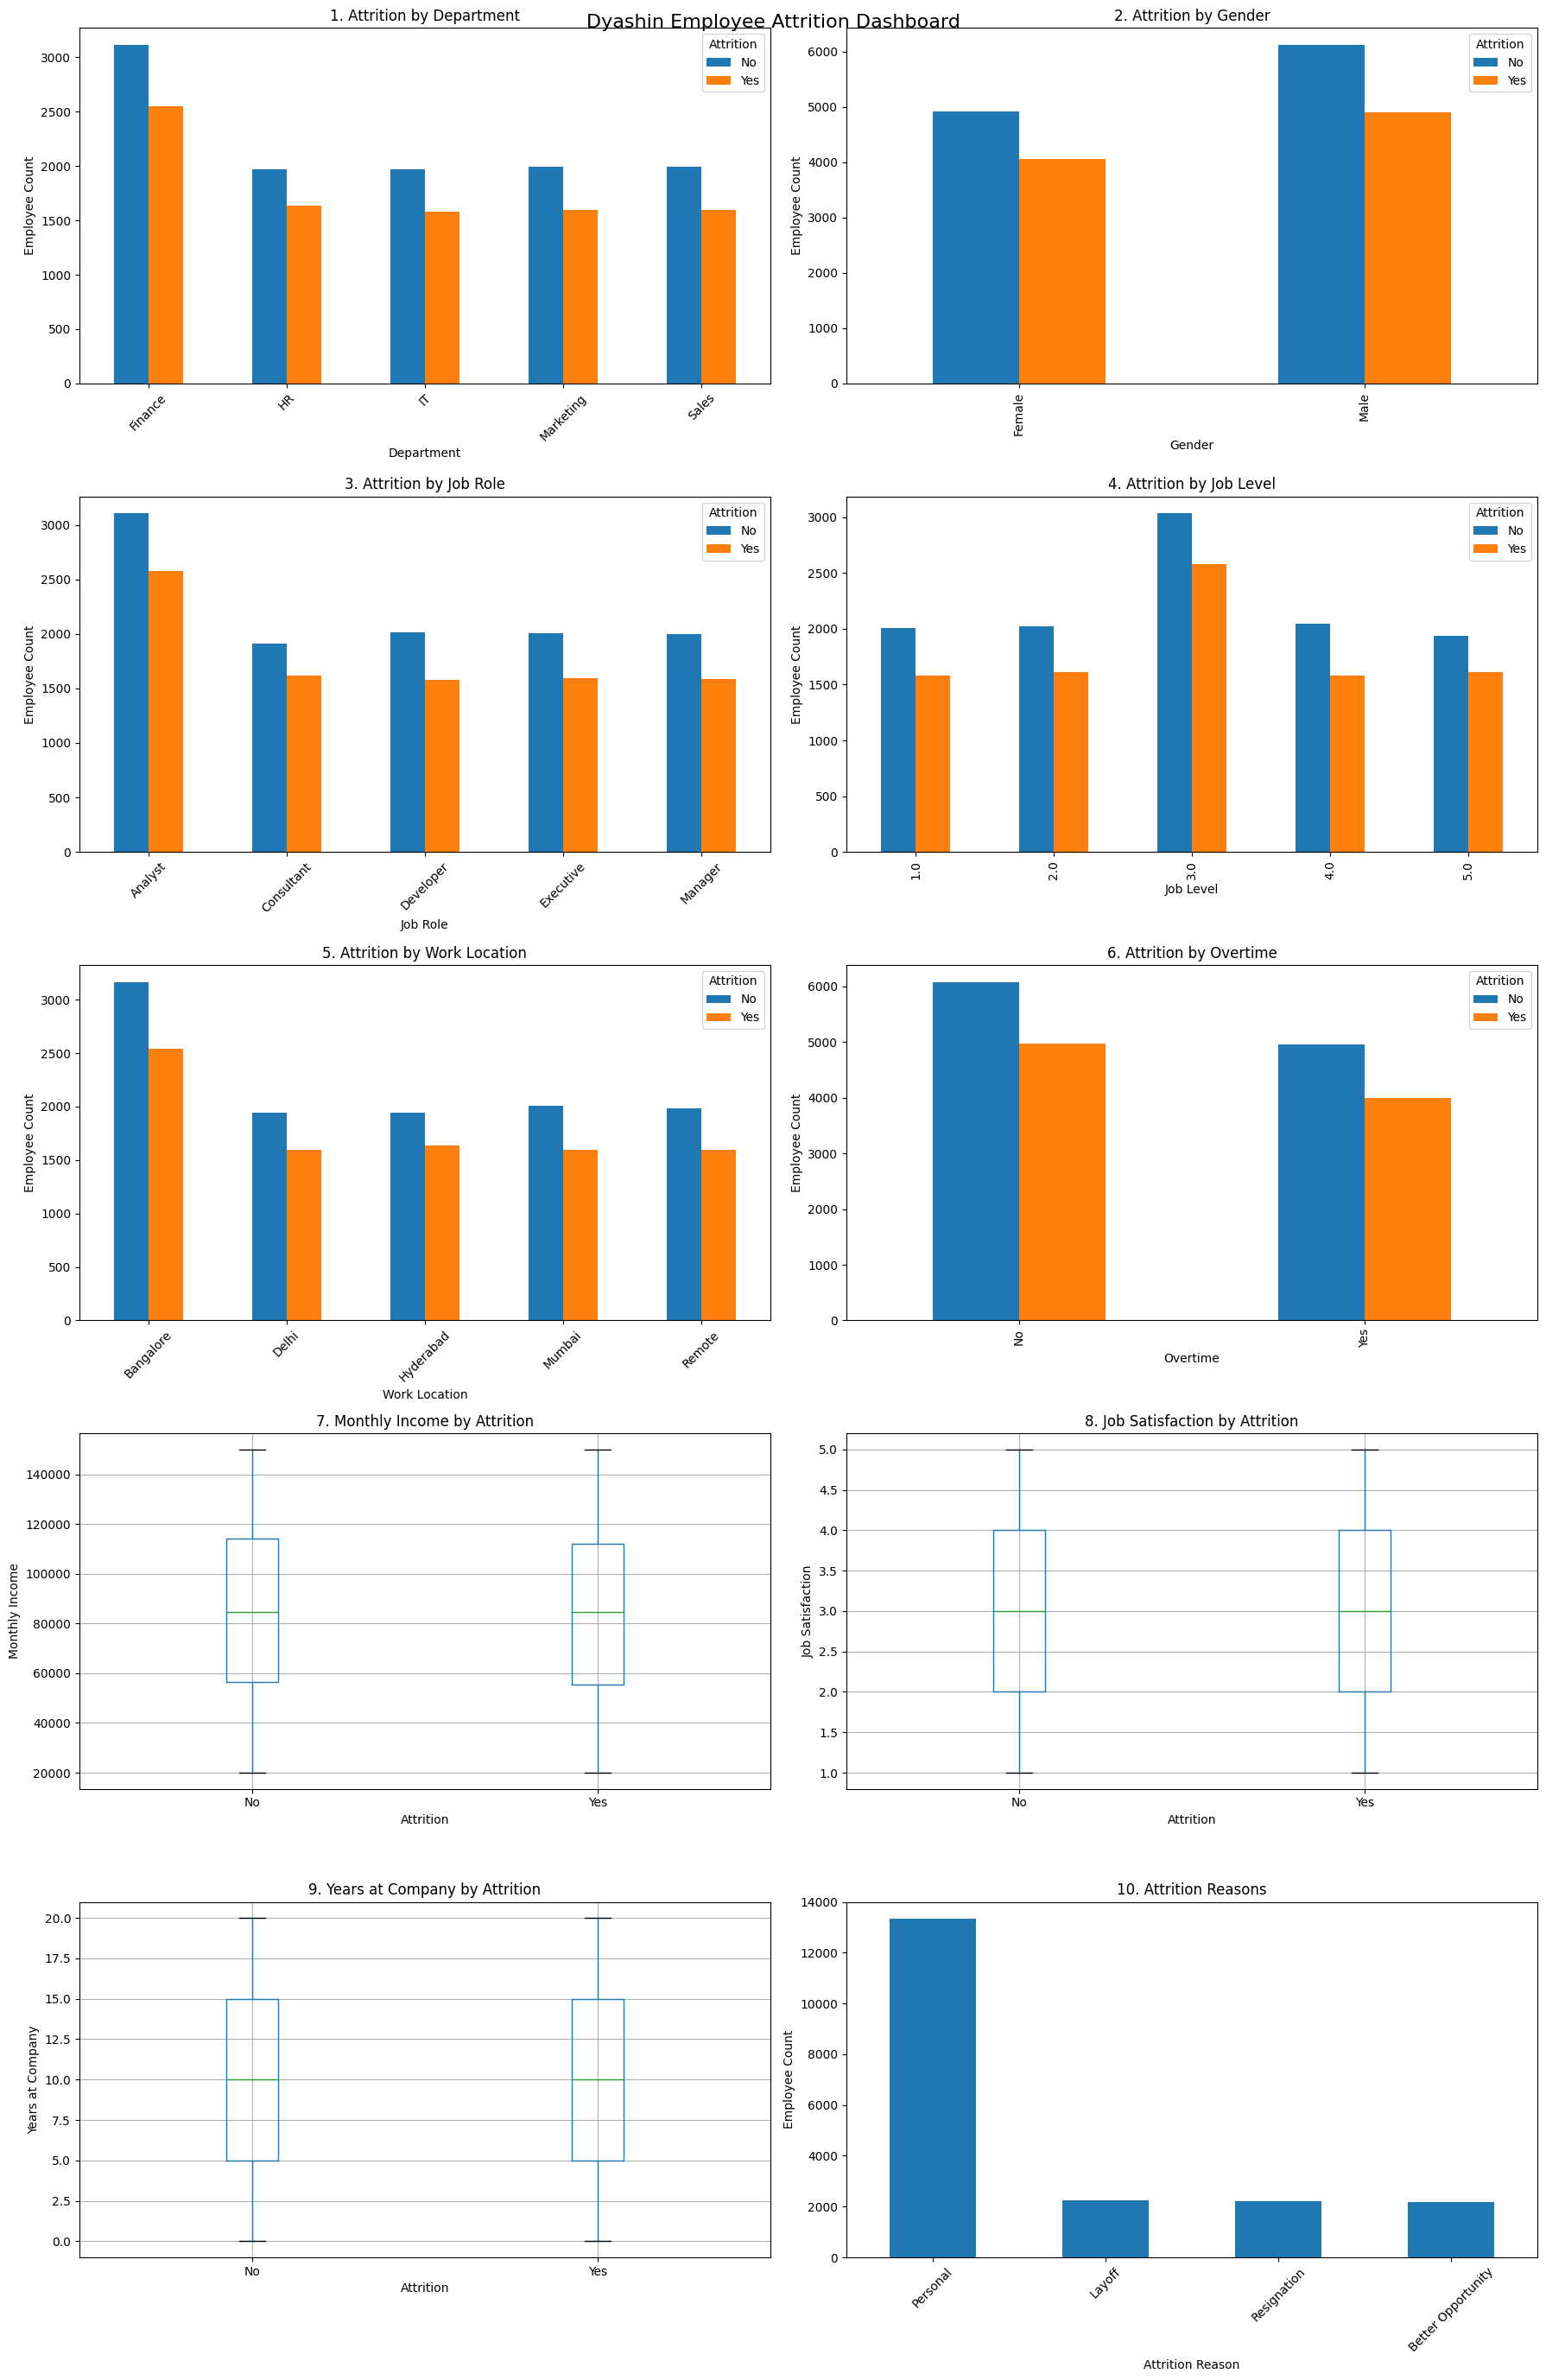


Dashboard created successfully.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# STEP 1: DATASET EXPLORATION
# ==================================================

df = pd.read_excel("dyashin_attrition_dataset.xlsx")

print("FIRST 5 ROWS")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES")
print(df.dtypes)

print("\nDATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nUNIQUE VALUES")
print(df.nunique())

print("\nSTATISTICAL SUMMARY")
print(df.describe())


# ==================================================
# STEP 2: DATA CLEANING
# ==================================================

print("\nMISSING VALUES BEFORE CLEANING")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values with median
numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values with mode
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    if df[column].isnull().any():
        mode_values = df[column].mode()
        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values[0])

print("\nMISSING VALUES AFTER CLEANING")
print(df.isnull().sum())

print("\nDUPLICATES AFTER CLEANING")
print(df.duplicated().sum())

print("\nCLEANED DATASET SHAPE")
print(df.shape)

# Save cleaned dataset
df.to_excel("dyashin_attrition_cleaned.xlsx", index=False)

print("\nCleaned dataset saved successfully.")


# ==================================================
# STEP 3: DATA ANALYSIS
# ==================================================

print("\n1. ATTRITION BY DEPARTMENT")
print(pd.crosstab(df["Department"], df["Attrition"]))

print("\n2. ATTRITION BY GENDER")
print(pd.crosstab(df["Gender"], df["Attrition"]))

print("\n3. ATTRITION BY JOB ROLE")
print(pd.crosstab(df["Job_Role"], df["Attrition"]))

print("\n4. ATTRITION BY JOB LEVEL")
print(pd.crosstab(df["Job_Level"], df["Attrition"]))

print("\n5. ATTRITION BY WORK LOCATION")
print(pd.crosstab(df["Work_Location"], df["Attrition"]))

print("\n6. ATTRITION BY OVERTIME")
print(pd.crosstab(df["Overtime"], df["Attrition"]))

print("\n7. AVERAGE MONTHLY INCOME BY ATTRITION")
print(df.groupby("Attrition")["Monthly_Income"].mean())

print("\n8. AVERAGE JOB SATISFACTION BY ATTRITION")
print(df.groupby("Attrition")["Job_Satisfaction"].mean())

print("\n9. AVERAGE YEARS AT COMPANY BY ATTRITION")
print(df.groupby("Attrition")["Years_At_Company"].mean())

print("\n10. ATTRITION REASONS")
print(df["Attrition_Reason"].value_counts())


# ==================================================
# STEP 4: DATA VISUALIZATION
# ==================================================

fig, axes = plt.subplots(5, 2, figsize=(18, 28))
axes = axes.flatten()

# Chart 1: Attrition by Department
pd.crosstab(df["Department"], df["Attrition"]).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("1. Attrition by Department")
axes[0].set_xlabel("Department")
axes[0].set_ylabel("Employee Count")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Attrition by Gender
pd.crosstab(df["Gender"], df["Attrition"]).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("2. Attrition by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Employee Count")

# Chart 3: Attrition by Job Role
pd.crosstab(df["Job_Role"], df["Attrition"]).plot(
    kind="bar", ax=axes[2]
)
axes[2].set_title("3. Attrition by Job Role")
axes[2].set_xlabel("Job Role")
axes[2].set_ylabel("Employee Count")
axes[2].tick_params(axis="x", rotation=45)

# Chart 4: Attrition by Job Level
pd.crosstab(df["Job_Level"], df["Attrition"]).plot(
    kind="bar", ax=axes[3]
)
axes[3].set_title("4. Attrition by Job Level")
axes[3].set_xlabel("Job Level")
axes[3].set_ylabel("Employee Count")

# Chart 5: Attrition by Work Location
pd.crosstab(df["Work_Location"], df["Attrition"]).plot(
    kind="bar", ax=axes[4]
)
axes[4].set_title("5. Attrition by Work Location")
axes[4].set_xlabel("Work Location")
axes[4].set_ylabel("Employee Count")
axes[4].tick_params(axis="x", rotation=45)

# Chart 6: Attrition by Overtime
pd.crosstab(df["Overtime"], df["Attrition"]).plot(
    kind="bar", ax=axes[5]
)
axes[5].set_title("6. Attrition by Overtime")
axes[5].set_xlabel("Overtime")
axes[5].set_ylabel("Employee Count")

# Chart 7: Monthly Income by Attrition
df.boxplot(
    column="Monthly_Income",
    by="Attrition",
    ax=axes[6]
)
axes[6].set_title("7. Monthly Income by Attrition")
axes[6].set_xlabel("Attrition")
axes[6].set_ylabel("Monthly Income")

# Chart 8: Job Satisfaction by Attrition
df.boxplot(
    column="Job_Satisfaction",
    by="Attrition",
    ax=axes[7]
)
axes[7].set_title("8. Job Satisfaction by Attrition")
axes[7].set_xlabel("Attrition")
axes[7].set_ylabel("Job Satisfaction")

# Chart 9: Years at Company by Attrition
df.boxplot(
    column="Years_At_Company",
    by="Attrition",
    ax=axes[8]
)
axes[8].set_title("9. Years at Company by Attrition")
axes[8].set_xlabel("Attrition")
axes[8].set_ylabel("Years at Company")

# Chart 10: Attrition Reasons
df["Attrition_Reason"].value_counts().plot(
    kind="bar",
    ax=axes[9]
)
axes[9].set_title("10. Attrition Reasons")
axes[9].set_xlabel("Attrition Reason")
axes[9].set_ylabel("Employee Count")
axes[9].tick_params(axis="x", rotation=45)

plt.suptitle("Dyashin Employee Attrition Dashboard", fontsize=16)
plt.tight_layout()

# Save dashboard
plt.savefig("dyashin_attrition_dashboard.png", dpi=150, bbox_inches="tight")

plt.show()

print("\nDashboard created successfully.")